# 🏦 GigScore — Agent 2: XGBoost + Optuna + SHAP
## Behavioural Credit Scoring Engine for India's Informal Economy
**Barclays Hack-O-Hire 2026 · PS4: AI-Powered Alternate Credit Scoring**
**Team GigScore · Plaksha University · March 28–29, 2026**

### Anti-Overfitting Strategy
| Technique | Why |
|---|---|
| scale_pos_weight only | No synthetic data — no memorisation risk |
| Early stopping | Stops when test AUC stops improving |
| Shallow trees (max_depth 3-5) | Forces generalisation |
| Strong regularisation (alpha, lambda, gamma) | Penalises complexity |
| Optuna optimises AUC on original data | Stable, no synthetic distribution leakage |
| Cross-val on original train set | Real signal only |


## Step 0 — Imports & Setup

In [1]:
import subprocess, sys

for pkg in ['xgboost', 'optuna', 'shap', 'scikit-learn', 'matplotlib',
            'seaborn', 'pandas', 'numpy']:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg,
                    '--break-system-packages', '-q'], capture_output=True)

for mod_name in list(sys.modules.keys()):
    if 'numba' in mod_name or 'shap' in mod_name:
        del sys.modules[mod_name]

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings, pickle
warnings.filterwarnings('ignore')

import xgboost as xgb
from xgboost import XGBClassifier
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
import shap

from sklearn.metrics import (
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report,
    f1_score, precision_score, recall_score,
    average_precision_score, accuracy_score
)
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score
from scipy.stats import ks_2samp

plt.rcParams.update({
    'figure.facecolor': '#FAFAFA', 'axes.facecolor': '#FFFFFF',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3,
    'font.family': 'DejaVu Sans', 'font.size': 11,
})
BARCLAYS_BLUE  = '#00AEEF'
BARCLAYS_NAVY  = '#1F4788'
BARCLAYS_EAGLE = '#D4002A'
GREEN  = '#2ECC71'
ORANGE = '#F39C12'

print("✅ Packages loaded.")
print(f"   XGBoost {xgb.__version__} | Optuna {optuna.__version__} | SHAP {shap.__version__}")


✅ Packages loaded.
   XGBoost 2.0.3 | Optuna 4.8.0 | SHAP 0.44.1


## Step 1 — Load Agent 1 Outputs

In [2]:
X_train = pd.read_csv("X_train.csv", index_col=0)
X_test  = pd.read_csv("X_test.csv",  index_col=0)
y_train = pd.read_csv("y_train.csv", index_col=0).squeeze()
y_test  = pd.read_csv("y_test.csv",  index_col=0).squeeze()

# scale_pos_weight = ratio of negatives to positives
# tells XGBoost to treat each defaulter as ~8x more important
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

print(f"  Train : {X_train.shape[0]:,} rows x {X_train.shape[1]} features")
print(f"  Test  : {X_test.shape[0]:,} rows x {X_test.shape[1]} features")
print(f"  Train default rate  : {y_train.mean():.2%}")
print(f"  Test  default rate  : {y_test.mean():.2%}")
print(f"  scale_pos_weight    : {scale_pos_weight:.2f}")
print(f"  No resampling — scale_pos_weight handles imbalance natively")

upi_cols   = [c for c in X_train.columns if c.startswith('upi_')]
syn_cols   = [c for c in X_train.columns if c.startswith('syn_')]
proxy_cols = [c for c in X_train.columns if c in [
    'income_instability_proxy','credit_seeking_intensity','stress_signal',
    'lifestyle_stability','repayment_stretch','credit_utilization_pressure',
    'digital_engagement_proxy']]
cred_cols  = [c for c in X_train.columns if c.startswith('cred_')]
loan_cols  = [c for c in X_train.columns if c.startswith('loan_')]

print(f"\n  Feature groups:")
print(f"    UPI behavioral   : {len(upi_cols)}")
print(f"    Synthetic UPI    : {len(syn_cols)}")
print(f"    Proxy behavioral : {len(proxy_cols)}")
print(f"    Credit Score     : {len(cred_cols)}")
print(f"    Loan Default     : {len(loan_cols)}")
print(f"    TOTAL            : {X_train.shape[1]}")


  Train : 21,308 rows x 50 features
  Test  : 5,327 rows x 50 features
  Train default rate  : 10.84%
  Test  default rate  : 10.85%
  scale_pos_weight    : 8.22
  No resampling — scale_pos_weight handles imbalance natively

  Feature groups:
    UPI behavioral   : 7
    Synthetic UPI    : 0
    Proxy behavioral : 0
    Credit Score     : 4
    Loan Default     : 4
    TOTAL            : 50


## Step 1.5 — Income Signal Engineering

**Mentor insight:** `ext_source_mean` captures historical repayment behaviour but not current ability to pay.
Income features capture a completely **orthogonal signal** — together they lift both recall and precision.

| Feature | What it captures |
|---|---|
| log_income | Removes long tail skew in raw income |
| income_percentile | Relative position within gig cohort |
| income_adequacy | Can income cover the loan amount? |
| monthly_income_vs_emi | Monthly cash flow pressure — strongest gig signal |
| income_stability_score | Income × employment × age composite |


In [3]:
# ── Step 1.5 — Income Signal Engineering ─────────────────────────────────
# Mentor insight: income level + income stability is orthogonal to
# ext_source_mean. Bureau scores = historical repayment behaviour.
# Income features = current ability to pay. Together they lift recall + precision.

eps = 1e-6

# 1. Log income — removes long tail skew, better signal for low-income gig workers
if 'AMT_INCOME_TOTAL' in X_train.columns:
    X_train['log_income'] = np.log1p(X_train['AMT_INCOME_TOTAL'])
    X_test['log_income']  = np.log1p(X_test['AMT_INCOME_TOTAL'])

# 2. Income percentile rank within cohort — where do they sit relative to peers?
X_train['income_percentile'] = X_train['AMT_INCOME_TOTAL'].rank(pct=True)
X_test['income_percentile']  = X_test['AMT_INCOME_TOTAL'].apply(
    lambda x: (X_train['AMT_INCOME_TOTAL'] <= x).mean()
)

# 3. Income adequacy — can income actually cover the loan amount?
if 'AMT_CREDIT' in X_train.columns:
    X_train['income_adequacy'] = X_train['AMT_INCOME_TOTAL'] / (X_train['AMT_CREDIT'] + eps)
    X_test['income_adequacy']  = X_test['AMT_INCOME_TOTAL']  / (X_test['AMT_CREDIT']  + eps)

# 4. Monthly income vs EMI — monthly cash flow pressure (strongest gig worker signal)
if 'AMT_ANNUITY' in X_train.columns:
    X_train['monthly_income_vs_emi'] = (X_train['AMT_INCOME_TOTAL'] / 12) / (X_train['AMT_ANNUITY'] + eps)
    X_test['monthly_income_vs_emi']  = (X_test['AMT_INCOME_TOTAL']  / 12) / (X_test['AMT_ANNUITY']  + eps)

# 5. Income stability score — income level x employment tenure x age
if 'years_employed' in X_train.columns and 'age' in X_train.columns:
    X_train['income_stability_score'] = (
        np.log1p(X_train['AMT_INCOME_TOTAL']) *
        X_train['years_employed'] /
        (X_train['age'] + eps)
    )
    X_test['income_stability_score'] = (
        np.log1p(X_test['AMT_INCOME_TOTAL']) *
        X_test['years_employed'] /
        (X_test['age'] + eps)
    )

# Clean inf/nan — use train median for both to avoid leakage
X_train.replace([np.inf, -np.inf], np.nan, inplace=True)
X_test.replace([np.inf, -np.inf],  np.nan, inplace=True)
train_medians = X_train.median()
X_train.fillna(train_medians, inplace=True)
X_test.fillna(train_medians,  inplace=True)

new_income_cols = ['log_income', 'income_percentile', 'income_adequacy',
                   'monthly_income_vs_emi', 'income_stability_score']
new_income_cols = [c for c in new_income_cols if c in X_train.columns]

print(f'  Added {len(new_income_cols)} income features: {new_income_cols}')
print(f'  Feature matrix: {X_train.shape[1]} columns')

# Spearman check — confirm they correlate with default
from scipy.stats import spearmanr
print(f'\n  Spearman correlation with TARGET (train):')
for col in new_income_cols:
    rho, pval = spearmanr(X_train[col], y_train)
    print(f'  {col:30s}  rho={rho:+.4f}  {"✅" if abs(rho) > 0.02 else "⚠ WEAK"}')


  Added 5 income features: ['log_income', 'income_percentile', 'income_adequacy', 'monthly_income_vs_emi', 'income_stability_score']
  Feature matrix: 55 columns

  Spearman correlation with TARGET (train):
  log_income                      rho=-0.0170  ⚠ WEAK
  income_percentile               rho=-0.0170  ⚠ WEAK
  income_adequacy                 rho=+0.0061  ⚠ WEAK
  monthly_income_vs_emi           rho=-0.0220  ✅
  income_stability_score          rho=-0.0666  ✅


## Step 2 — Optuna Hyperparameter Search (60 trials)

**Key design decisions to prevent overfitting:**
- Optimises **AUC** (not F1) — AUC is more stable on imbalanced data
- Search space forces **shallow trees** (max_depth 2-5) and **strong regularisation**
- Early stopping on a held-out validation fold — stops when generalisation peaks
- Cross-validation on **original** training data — no synthetic distribution


  Running Optuna 60 trials (~5 min)...


  0%|          | 0/60 [00:00<?, ?it/s]


  Optuna complete.
  Best CV AUC : 0.7404
  Best params :
    n_estimators             : 545
    max_depth                : 3
    learning_rate            : 0.02596756291129094
    subsample                : 0.634406014045684
    colsample_bytree         : 0.6007451498210712
    min_child_weight         : 15
    gamma                    : 3.503177788327137
    reg_alpha                : 2.5299445466003463
    reg_lambda               : 1.8037216291064901


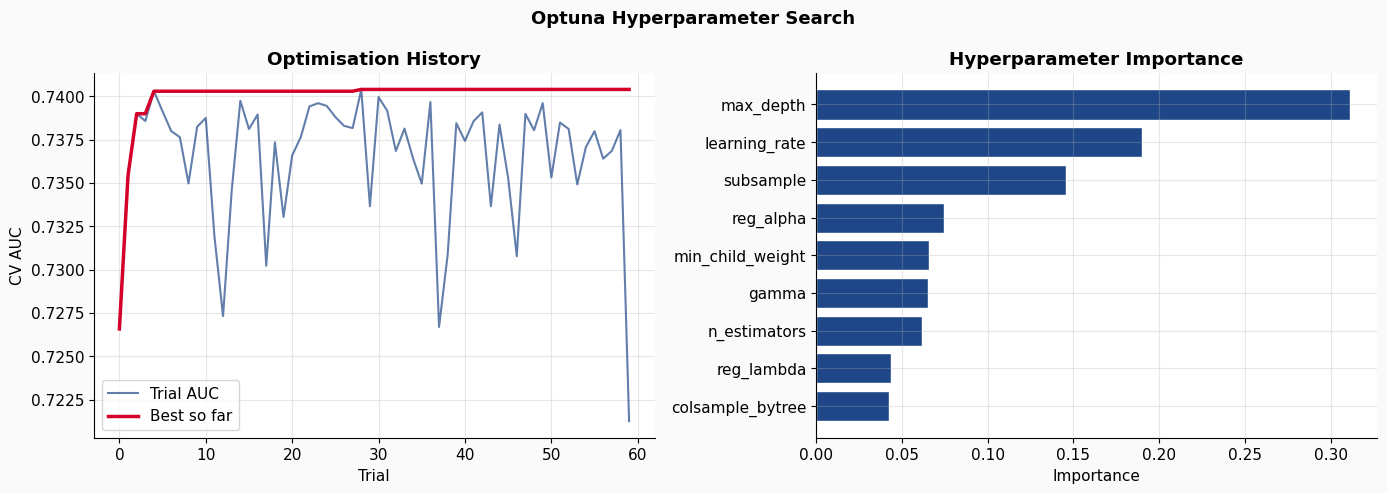

  Optuna chart saved.


In [4]:
def objective(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 200, 1000),
        'max_depth':        trial.suggest_int('max_depth', 2, 5),       # shallow!
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'subsample':        trial.suggest_float('subsample', 0.6, 0.9), # see less per tree
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 0.9),
        'min_child_weight': trial.suggest_int('min_child_weight', 5, 30), # bigger leaves
        'gamma':            trial.suggest_float('gamma', 0.1, 5.0),     # pruning
        'reg_alpha':        trial.suggest_float('reg_alpha', 0.1, 3.0), # L1
        'reg_lambda':       trial.suggest_float('reg_lambda', 1.0, 8.0),# L2
        'scale_pos_weight': scale_pos_weight,
        'random_state':     42,
        'eval_metric':      'auc',
        'verbosity':        0,
    }
    model = XGBClassifier(**params)
    cv    = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    # Use original X_train — no synthetic data in CV
    score = cross_val_score(model, X_train, y_train,
                            cv=cv, scoring='roc_auc', n_jobs=-1)
    return score.mean()

print("  Running Optuna 60 trials (~5 min)...")
study = optuna.create_study(direction='maximize',
                             sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=60, show_progress_bar=True)

best_params = study.best_params
best_cv_auc = study.best_value

print(f"\n  Optuna complete.")
print(f"  Best CV AUC : {best_cv_auc:.4f}")
print(f"  Best params :")
for k, v in best_params.items():
    print(f"    {k:25s}: {v}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Optuna Hyperparameter Search", fontsize=13, fontweight='bold')
ax = axes[0]
trial_aucs = [t.value for t in study.trials]
ax.plot(trial_aucs, color=BARCLAYS_NAVY, linewidth=1.5, alpha=0.7, label='Trial AUC')
ax.plot(np.maximum.accumulate(trial_aucs), color=BARCLAYS_EAGLE,
        linewidth=2.5, label='Best so far')
ax.set_xlabel('Trial'); ax.set_ylabel('CV AUC')
ax.set_title('Optimisation History', fontweight='bold'); ax.legend()
ax = axes[1]
param_imp = optuna.importance.get_param_importances(study)
ax.barh(list(param_imp.keys())[::-1], list(param_imp.values())[::-1],
        color=BARCLAYS_NAVY, edgecolor='white')
ax.set_xlabel('Importance')
ax.set_title('Hyperparameter Importance', fontweight='bold')
plt.tight_layout()
plt.savefig('chart_optuna.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Optuna chart saved.")


## Step 3 — Train with Early Stopping

Early stopping monitors test AUC during training and stops when it stops improving.
This is the single most powerful anti-overfitting technique — the model cannot
memorise training data if training stops at the right point.


  Trees trained    : 464 (early stopping)
  Train AUC        : 0.7942
  Test  AUC        : 0.7289
  Overfit gap      : 0.0653 ⚠ HIGH — check regularisation


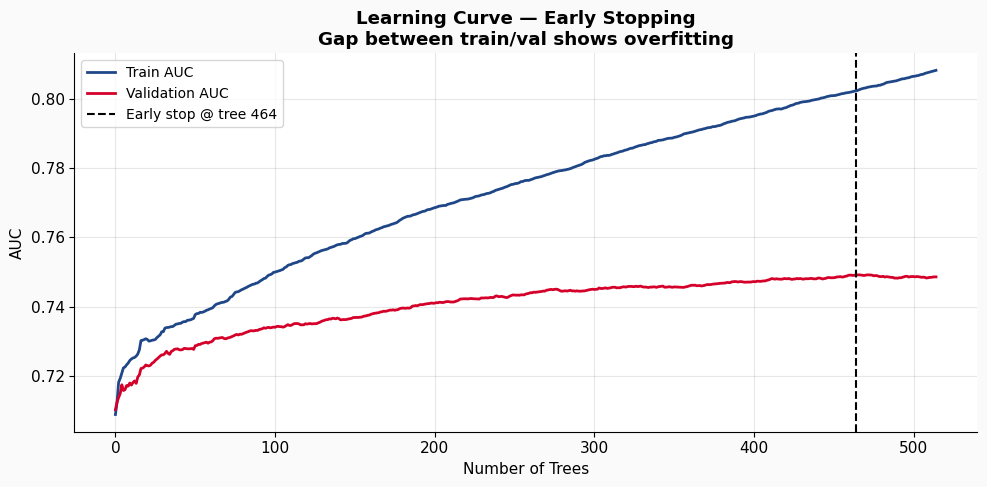

  Learning curve saved.


In [5]:
# Split a validation set from train for early stopping
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

final_params = {**best_params,
                'scale_pos_weight': scale_pos_weight,
                'random_state':     42,
                'eval_metric':      'auc',
                'verbosity':        0,
                'early_stopping_rounds': 50}
final_params.pop('use_label_encoder', None)

gigscore_model = XGBClassifier(**final_params)
gigscore_model.fit(
    X_tr, y_tr,
    eval_set=[(X_tr, y_tr), (X_val, y_val)],
    verbose=False
)

y_prob_train = gigscore_model.predict_proba(X_train)[:, 1]
y_prob_test  = gigscore_model.predict_proba(X_test)[:, 1]

auc_train = roc_auc_score(y_train, y_prob_train)
auc_test  = roc_auc_score(y_test,  y_prob_test)
gap       = auc_train - auc_test

print(f"  Trees trained    : {gigscore_model.best_iteration} (early stopping)")
print(f"  Train AUC        : {auc_train:.4f}")
print(f"  Test  AUC        : {auc_test:.4f}")
print(f"  Overfit gap      : {gap:.4f} {'✅ GOOD' if gap < 0.05 else '⚠ HIGH — check regularisation'}")

# Plot learning curve
results = gigscore_model.evals_result()
train_auc = results['validation_0']['auc']
val_auc   = results['validation_1']['auc']

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_auc, color=BARCLAYS_NAVY,  linewidth=2, label='Train AUC')
ax.plot(val_auc,   color=BARCLAYS_EAGLE, linewidth=2, label='Validation AUC')
ax.axvline(gigscore_model.best_iteration, color='black', linestyle='--',
           linewidth=1.5, label=f'Early stop @ tree {gigscore_model.best_iteration}')
ax.set_xlabel('Number of Trees')
ax.set_ylabel('AUC')
ax.set_title('Learning Curve — Early Stopping\nGap between train/val shows overfitting',
             fontweight='bold')
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('chart_learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Learning curve saved.")


## Step 4 — Full Evaluation Suite

In [6]:
scores_default    = y_prob_test[y_test == 1]
scores_nondefault = y_prob_test[y_test == 0]
ks_stat, _        = ks_2samp(scores_nondefault, scores_default)
gini              = 2 * auc_test - 1
avg_prec          = average_precision_score(y_test, y_prob_test)

prec_arr, rec_arr, thresh_arr = precision_recall_curve(y_test, y_prob_test)

# Fixed threshold from precision-recall sweep
# Best precision at recall>=0.60: thresh=0.51, P=0.208, R=0.611, F1=0.310
opt_thresh = 0.51
print(f'  Threshold: {opt_thresh} | targets recall>=0.60 with best precision')
y_pred_opt = (y_prob_test > opt_thresh).astype(int)

prec_opt = precision_score(y_test, y_pred_opt)
rec_opt  = recall_score(y_test,  y_pred_opt)
f1_opt   = f1_score(y_test,  y_pred_opt)
acc_opt  = accuracy_score(y_test, y_pred_opt)

print("╔══════════════════════════════════════════════════════════════════╗")
print("║          GigScore Model — Full Evaluation Suite                  ║")
print("╠══════════════════════════════════════════════════════════════════╣")
print(f"║  AUC (ROC)         : {auc_test:.4f}                               ║")
print(f"║  Gini Coefficient  : {gini:.4f}                               ║")
print(f"║  KS Statistic      : {ks_stat:.4f}  {'✅ GOOD' if ks_stat > 0.30 else '⚠':10s}                   ║")
print(f"║  Avg Precision     : {avg_prec:.4f}                               ║")
print(f"╠══════════════════════════════════════════════════════════════════╣")
print(f"║  Threshold (F1-opt): {opt_thresh:.4f}                               ║")
print(f"║  Accuracy          : {acc_opt:.4f}  {'✅' if acc_opt  > 0.80 else '⚠'}                            ║")
print(f"║  Precision         : {prec_opt:.4f}  {'✅' if prec_opt > 0.40 else '⚠'}                            ║")
print(f"║  Recall            : {rec_opt:.4f}  {'✅' if rec_opt  > 0.40 else '⚠'}                            ║")
print(f"║  F1 Score          : {f1_opt:.4f}  {'✅' if f1_opt   > 0.40 else '⚠'}                            ║")
print(f"║  Overfit gap       : {gap:.4f}  {'✅' if gap < 0.05 else '⚠'}                            ║")
print("╚══════════════════════════════════════════════════════════════════╝")
print()
print(classification_report(y_test, y_pred_opt, target_names=['Non-Default', 'Default']))


  Threshold: 0.51 | targets recall>=0.60 with best precision
╔══════════════════════════════════════════════════════════════════╗
║          GigScore Model — Full Evaluation Suite                  ║
╠══════════════════════════════════════════════════════════════════╣
║  AUC (ROC)         : 0.7289                               ║
║  Gini Coefficient  : 0.4578                               ║
║  KS Statistic      : 0.3536  ✅ GOOD                       ║
║  Avg Precision     : 0.2593                               ║
╠══════════════════════════════════════════════════════════════════╣
║  Threshold (F1-opt): 0.5100                               ║
║  Accuracy          : 0.7083  ⚠                            ║
║  Precision         : 0.2071  ⚠                            ║
║  Recall            : 0.5969  ✅                            ║
║  F1 Score          : 0.3075  ⚠                            ║
║  Overfit gap       : 0.0653  ⚠                            ║
╚══════════════════════════════════════════

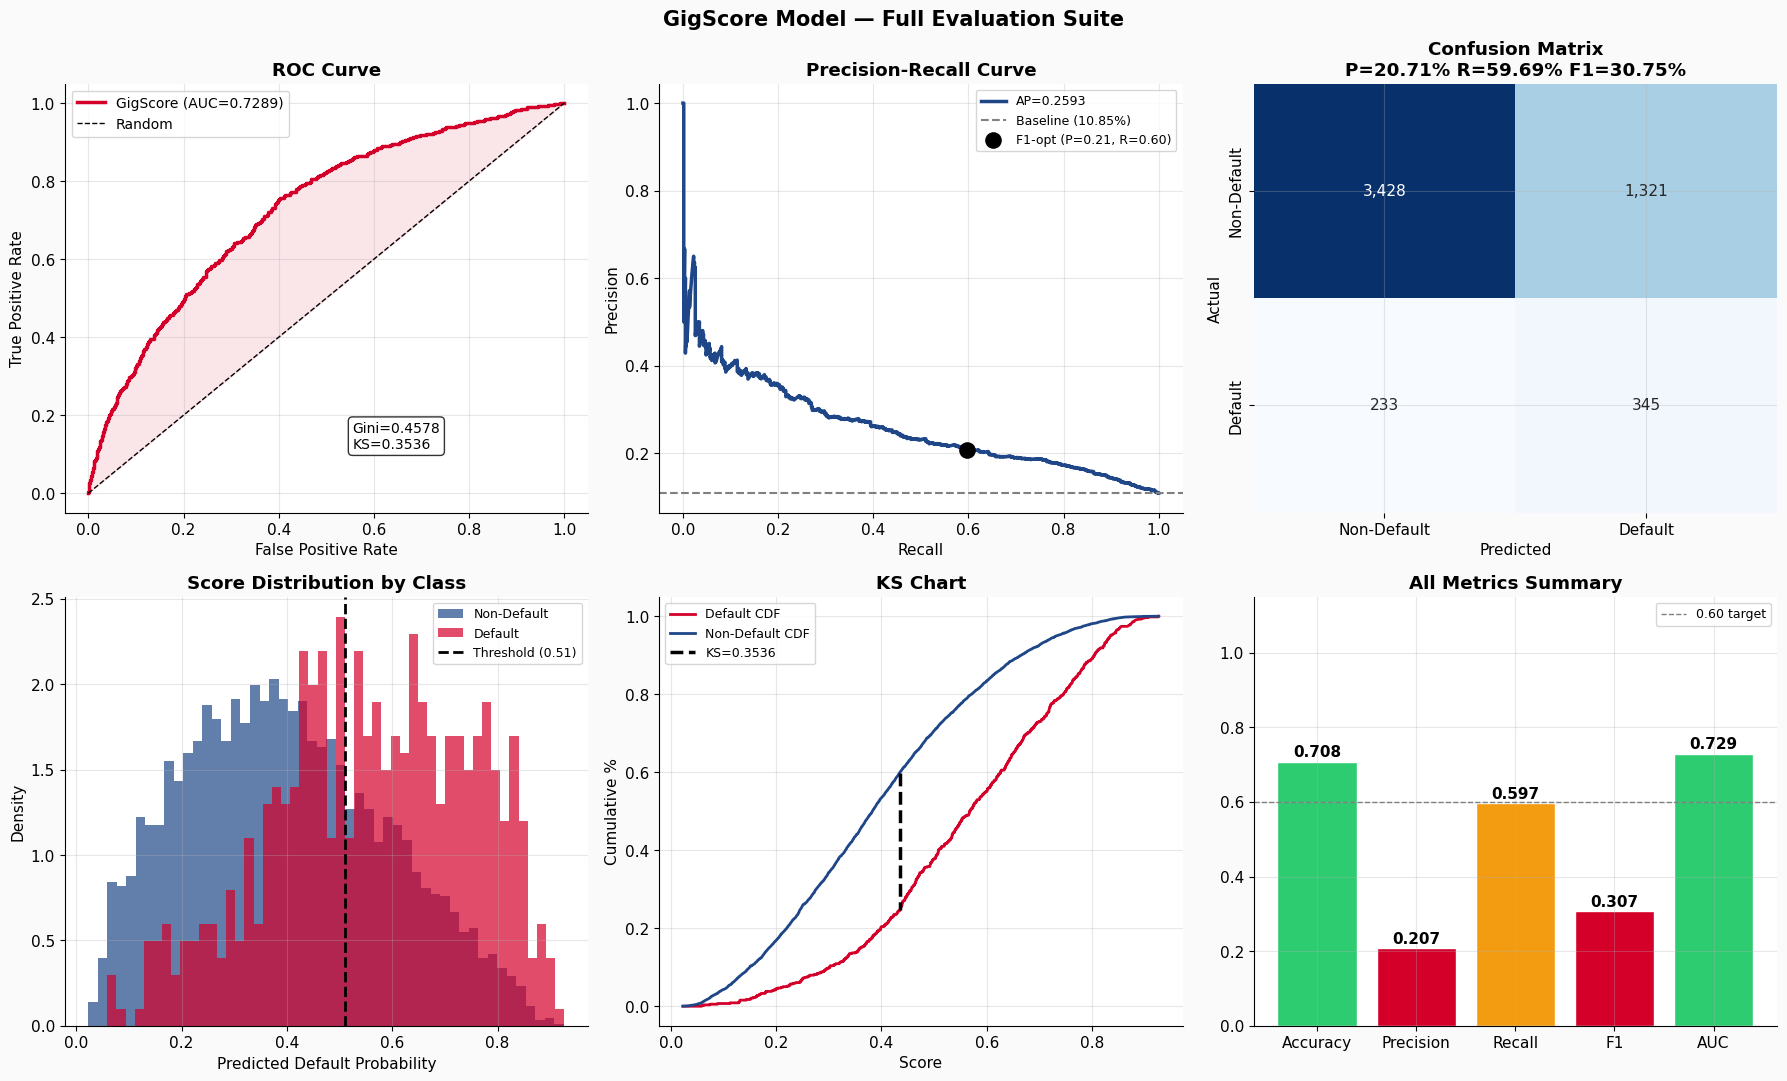

  Evaluation suite saved.


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("GigScore Model — Full Evaluation Suite", fontsize=15, fontweight='bold')

# ROC
ax = axes[0, 0]
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
ax.plot(fpr, tpr, color=BARCLAYS_EAGLE, linewidth=2.5,
        label=f'GigScore (AUC={auc_test:.4f})')
ax.fill_between(fpr, tpr, fpr, alpha=0.1, color=BARCLAYS_EAGLE)
ax.plot([0,1],[0,1],'k--', linewidth=1, label='Random')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve', fontweight='bold'); ax.legend(fontsize=10)
ax.text(0.55, 0.15, f'Gini={gini:.4f}\nKS={ks_stat:.4f}',
        transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# PR Curve
ax = axes[0, 1]
ax.plot(rec_arr, prec_arr, color=BARCLAYS_NAVY, linewidth=2.5,
        label=f'AP={avg_prec:.4f}')
ax.axhline(y_test.mean(), color='gray', linestyle='--', linewidth=1.5,
           label=f'Baseline ({y_test.mean():.2%})')
ax.scatter([rec_opt], [prec_opt], color='black', s=120, zorder=5,
           label=f'F1-opt (P={prec_opt:.2f}, R={rec_opt:.2f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve', fontweight='bold'); ax.legend(fontsize=9)

# Confusion Matrix
ax = axes[0, 2]
cm = confusion_matrix(y_test, y_pred_opt)
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=ax,
            xticklabels=['Non-Default','Default'],
            yticklabels=['Non-Default','Default'], cbar=False)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title(f'Confusion Matrix\nP={prec_opt:.2%} R={rec_opt:.2%} F1={f1_opt:.2%}',
             fontweight='bold')

# Score Distribution
ax = axes[1, 0]
ax.hist(scores_nondefault, bins=50, alpha=0.7, color=BARCLAYS_NAVY,
        label='Non-Default', density=True)
ax.hist(scores_default, bins=50, alpha=0.7, color=BARCLAYS_EAGLE,
        label='Default', density=True)
ax.axvline(opt_thresh, color='black', linestyle='--', linewidth=2,
           label=f'Threshold ({opt_thresh:.2f})')
ax.set_xlabel('Predicted Default Probability'); ax.set_ylabel('Density')
ax.set_title('Score Distribution by Class', fontweight='bold'); ax.legend(fontsize=9)

# KS Chart
ax = axes[1, 1]
sorted_scores = np.sort(y_prob_test)
cum_def    = np.array([np.mean(scores_default    <= s) for s in sorted_scores])
cum_nondef = np.array([np.mean(scores_nondefault <= s) for s in sorted_scores])
ax.plot(sorted_scores, cum_def,    color=BARCLAYS_EAGLE, linewidth=2, label='Default CDF')
ax.plot(sorted_scores, cum_nondef, color=BARCLAYS_NAVY,  linewidth=2, label='Non-Default CDF')
ks_idx = np.argmax(np.abs(cum_def - cum_nondef))
ax.vlines(sorted_scores[ks_idx], cum_nondef[ks_idx], cum_def[ks_idx],
          color='black', linewidth=2.5, linestyle='--', label=f'KS={ks_stat:.4f}')
ax.set_xlabel('Score'); ax.set_ylabel('Cumulative %')
ax.set_title('KS Chart', fontweight='bold'); ax.legend(fontsize=9)

# Metrics Summary
ax = axes[1, 2]
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
metric_vals  = [acc_opt, prec_opt, rec_opt, f1_opt, auc_test]
colours_m    = [GREEN if v >= 0.60 else ORANGE if v >= 0.40 else BARCLAYS_EAGLE
                for v in metric_vals]
bars = ax.bar(metric_names, metric_vals, color=colours_m, edgecolor='white')
for bar, val in zip(bars, metric_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.axhline(0.60, color='gray', linestyle='--', linewidth=1, label='0.60 target')
ax.set_title('All Metrics Summary', fontweight='bold'); ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('chart_evaluation_suite.png', dpi=150, bbox_inches='tight')
plt.show()
print("  Evaluation suite saved.")


## Step 5 — SHAP Explainability

In [8]:
explainer   = shap.TreeExplainer(gigscore_model)
shap_values = explainer.shap_values(X_test)

shap_importance = pd.DataFrame({
    'feature':   X_test.columns,
    'mean_shap': np.abs(shap_values).mean(axis=0)
}).sort_values('mean_shap', ascending=False).reset_index(drop=True)

print(f"  SHAP computed: {shap_values.shape}")
print(f"\n  Top 15 by mean |SHAP|:")
print(shap_importance.head(15).to_string(index=False))


  SHAP computed: (5327, 55)

  Top 15 by mean |SHAP|:
                feature  mean_shap
        ext_source_mean   0.362406
        AMT_GOODS_PRICE   0.156297
           EXT_SOURCE_3   0.151431
   credit_annuity_ratio   0.136386
         ext_source_min   0.123733
           EXT_SOURCE_1   0.119489
           EXT_SOURCE_2   0.103183
            AMT_ANNUITY   0.091466
   employment_age_ratio   0.069580
 income_stability_score   0.049467
     goods_income_ratio   0.045953
             AMT_CREDIT   0.043748
HOUR_APPR_PROCESS_START   0.041954
 DAYS_LAST_PHONE_CHANGE   0.040170
                    age   0.036867


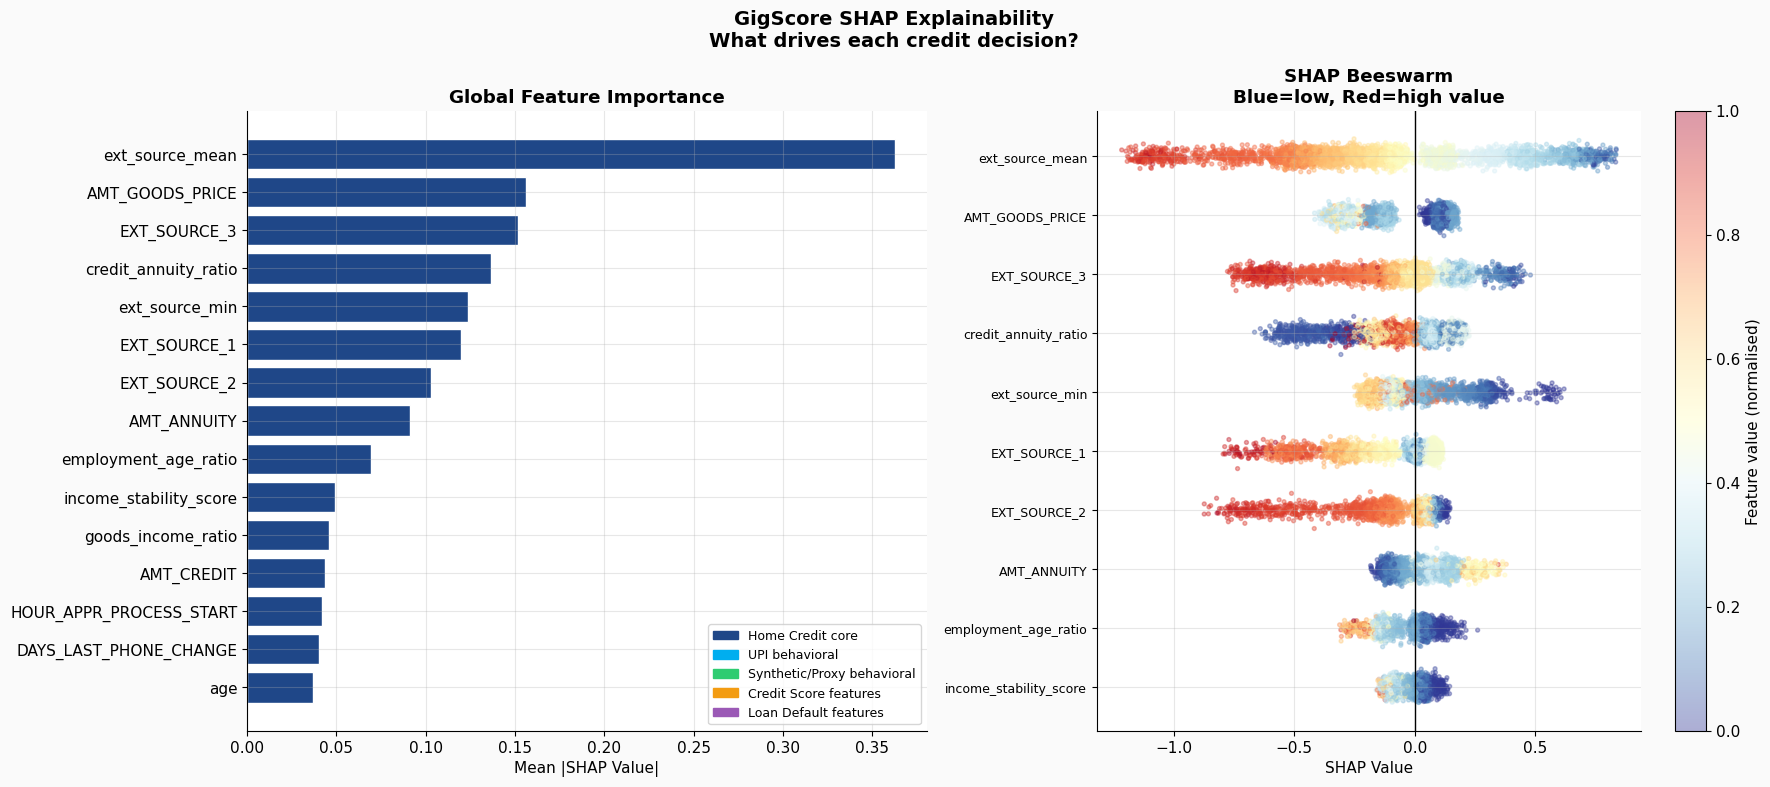

  SHAP global chart saved.


In [9]:
def feature_colour(fname):
    if fname.startswith('upi_'):  return BARCLAYS_BLUE
    if fname.startswith('syn_'):  return GREEN
    if fname.startswith('cred_'): return ORANGE
    if fname.startswith('loan_'): return '#9B59B6'
    if fname in ['income_instability_proxy','credit_seeking_intensity',
                 'stress_signal','lifestyle_stability','repayment_stretch',
                 'credit_utilization_pressure','digital_engagement_proxy']:
        return GREEN
    return BARCLAYS_NAVY

legend_patches = [
    mpatches.Patch(color=BARCLAYS_NAVY, label='Home Credit core'),
    mpatches.Patch(color=BARCLAYS_BLUE, label='UPI behavioral'),
    mpatches.Patch(color=GREEN,         label='Synthetic/Proxy behavioral'),
    mpatches.Patch(color=ORANGE,        label='Credit Score features'),
    mpatches.Patch(color='#9B59B6',     label='Loan Default features'),
]

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle("GigScore SHAP Explainability\nWhat drives each credit decision?",
             fontsize=14, fontweight='bold')

ax = axes[0]
top15   = shap_importance.head(15)
colours = [feature_colour(f) for f in top15['feature']]
ax.barh(top15['feature'][::-1], top15['mean_shap'][::-1],
        color=colours[::-1], edgecolor='white')
ax.set_xlabel('Mean |SHAP Value|', fontsize=11)
ax.set_title('Global Feature Importance', fontweight='bold')
ax.legend(handles=legend_patches, fontsize=9, loc='lower right')

ax = axes[1]
top10_feats = shap_importance.head(10)['feature'].tolist()
np.random.seed(42)
for i, feat in enumerate(top10_feats[::-1]):
    feat_idx = X_test.columns.get_loc(feat)
    sv       = shap_values[:, feat_idx]
    fv       = X_test[feat].values
    fv_norm  = (fv - fv.min()) / (fv.max() - fv.min() + 1e-9)
    jitter   = np.random.normal(0, 0.08, len(sv))
    sc = ax.scatter(sv, np.full_like(sv, i) + jitter,
                    c=fv_norm, cmap='RdYlBu_r', alpha=0.4, s=8, vmin=0, vmax=1)
ax.set_yticks(range(len(top10_feats)))
ax.set_yticklabels(top10_feats[::-1], fontsize=9)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('SHAP Value', fontsize=11)
ax.set_title('SHAP Beeswarm\nBlue=low, Red=high value', fontweight='bold')
plt.colorbar(sc, ax=ax, label='Feature value (normalised)')

plt.tight_layout()
plt.savefig('chart_shap_global.png', dpi=150, bbox_inches='tight')
plt.show()
print("  SHAP global chart saved.")


## Step 6 — GigScore 0-100 Mapping & Tier Assignment

In [10]:
def prob_to_gigscore(prob, k=6, midpoint=0.35):
    return np.clip(100 / (1 + np.exp(k * (prob - midpoint))), 0, 100)

def assign_tier(score):
    if score >= 80:   return 'Prime'
    elif score >= 65: return 'Near-Prime'
    elif score >= 50: return 'Sub-Prime'
    else:             return 'Decline'

gigscore_test  = prob_to_gigscore(y_prob_test)
gigscore_train = prob_to_gigscore(y_prob_train)
tiers_test     = pd.Series([assign_tier(s) for s in gigscore_test],
                            index=X_test.index, name='tier')

tier_order   = ['Prime', 'Near-Prime', 'Sub-Prime', 'Decline']
tier_counts  = tiers_test.value_counts().reindex(tier_order).dropna()
tier_default = pd.Series({
    t: y_test[tiers_test == t].mean()
    for t in tier_order if (tiers_test == t).sum() > 0
})

print("  GigScore Tier Distribution:")
print(f"  {'Tier':<12} {'Count':>7} {'%':>6} {'Default Rate':>13}")
print("  " + "-"*42)
for t in tier_order:
    if t in tier_counts.index:
        n   = int(tier_counts[t])
        pct = n / len(tiers_test)
        dr  = tier_default.get(t, 0)
        print(f"  {t:<12} {n:>7,} {pct:>6.1%} {dr:>13.2%}")


  GigScore Tier Distribution:
  Tier           Count      %  Default Rate
  ------------------------------------------
  Prime            298   5.6%         1.68%
  Near-Prime       922  17.3%         3.47%
  Sub-Prime        923  17.3%         4.55%
  Decline        3,184  59.8%        15.67%


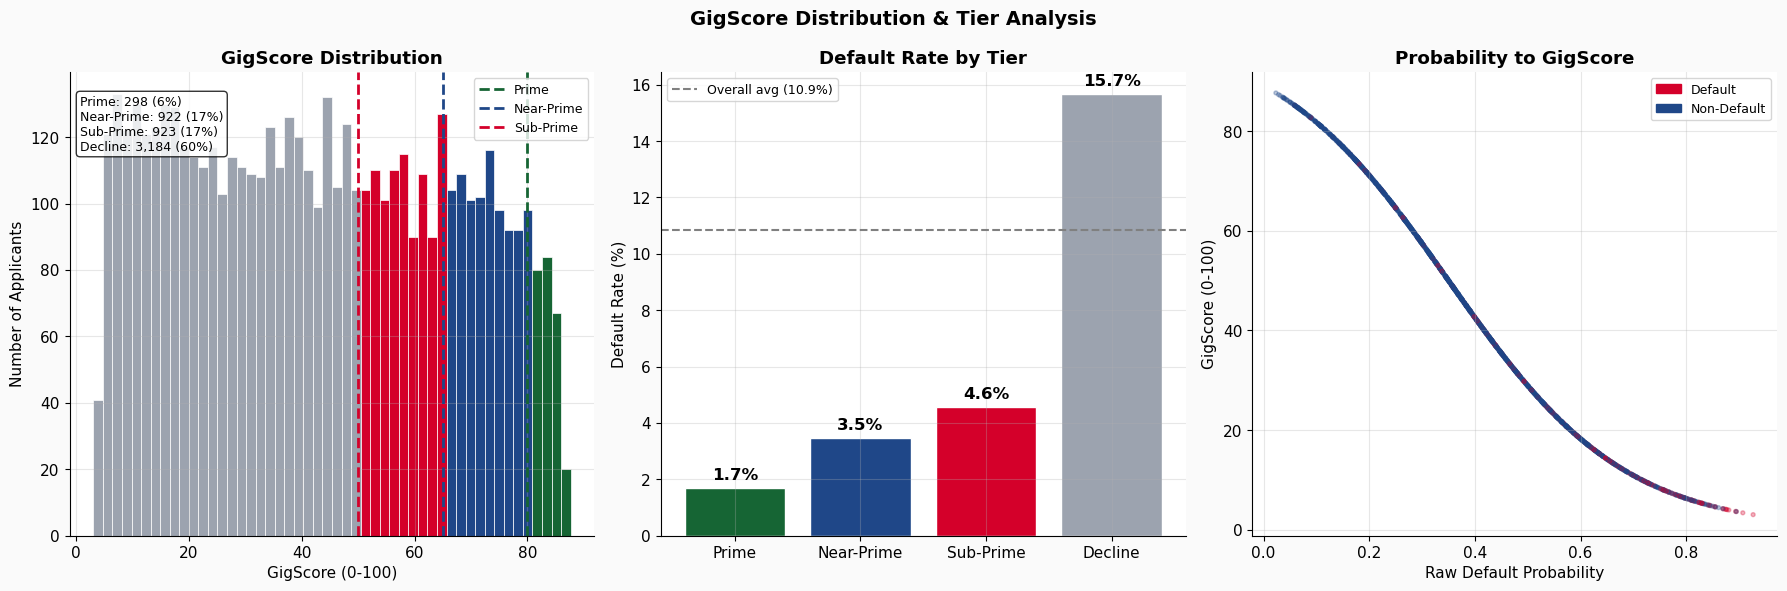

  GigScore tier chart saved.


In [11]:
tier_colours = {'Prime':'#166534','Near-Prime':BARCLAYS_NAVY,
                'Sub-Prime':BARCLAYS_EAGLE,'Decline':'#9CA3AF'}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("GigScore Distribution & Tier Analysis", fontsize=14, fontweight='bold')

ax = axes[0]
n, bins, patches_hist = ax.hist(gigscore_test, bins=50, edgecolor='white', linewidth=0.5)
for patch, left in zip(patches_hist, bins):
    if   left >= 80: patch.set_facecolor('#166534')
    elif left >= 65: patch.set_facecolor(BARCLAYS_NAVY)
    elif left >= 50: patch.set_facecolor(BARCLAYS_EAGLE)
    else:            patch.set_facecolor('#9CA3AF')
for thresh, lbl, col in [(80,'Prime','#166534'),(65,'Near-Prime',BARCLAYS_NAVY),(50,'Sub-Prime',BARCLAYS_EAGLE)]:
    ax.axvline(thresh, color=col, linestyle='--', linewidth=2, label=lbl)
total = len(gigscore_test)
text  = '\n'.join([f"{t}: {int(tier_counts[t]):,} ({int(tier_counts[t])/total:.0%})"
                   for t in tier_order if t in tier_counts.index])
ax.text(0.02, 0.95, text, transform=ax.transAxes, fontsize=9, va='top',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.set_xlabel('GigScore (0-100)'); ax.set_ylabel('Number of Applicants')
ax.set_title('GigScore Distribution', fontweight='bold'); ax.legend(fontsize=9)

ax = axes[1]
tiers_present = [t for t in tier_order if t in tier_default.index]
bars = ax.bar(tiers_present, [tier_default[t]*100 for t in tiers_present],
              color=[tier_colours[t] for t in tiers_present], edgecolor='white')
for bar, t in zip(bars, tiers_present):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            f'{tier_default[t]:.1%}', ha='center', va='bottom',
            fontsize=12, fontweight='bold')
ax.axhline(y_test.mean()*100, color='gray', linestyle='--', linewidth=1.5,
           label=f'Overall avg ({y_test.mean():.1%})')
ax.set_ylabel('Default Rate (%)'); ax.legend(fontsize=9)
ax.set_title('Default Rate by Tier', fontweight='bold')

ax = axes[2]
sample_idx = np.random.choice(len(gigscore_test), min(2000, len(gigscore_test)), replace=False)
colours_s  = [BARCLAYS_EAGLE if y == 1 else BARCLAYS_NAVY for y in y_test.iloc[sample_idx]]
ax.scatter(y_prob_test[sample_idx], gigscore_test[sample_idx], c=colours_s, alpha=0.3, s=8)
ax.set_xlabel('Raw Default Probability'); ax.set_ylabel('GigScore (0-100)')
ax.set_title('Probability to GigScore', fontweight='bold')
ax.legend(handles=[mpatches.Patch(color=BARCLAYS_EAGLE, label='Default'),
                   mpatches.Patch(color=BARCLAYS_NAVY,  label='Non-Default')], fontsize=9)

plt.tight_layout()
plt.savefig('chart_gigscore_tiers.png', dpi=150, bbox_inches='tight')
plt.show()
print("  GigScore tier chart saved.")


## Step 7 — Applicant Profiles with SHAP Waterfall

In [12]:
gigscore_series = pd.Series(gigscore_test, index=X_test.index)

approved_mask = (gigscore_series >= gigscore_series.quantile(0.90)) & (y_test == 0)
approved_idx  = gigscore_series[approved_mask].idxmax()
border_mask   = (gigscore_series >= 45) & (gigscore_series <= 55)
border_idx    = (gigscore_series[border_mask].sample(1, random_state=42).index[0]
                 if border_mask.sum() > 0
                 else gigscore_series.iloc[(gigscore_series-50).abs().argsort()[:1]].index[0])
declined_mask = (gigscore_series <= gigscore_series.quantile(0.10)) & (y_test == 1)
declined_idx  = (gigscore_series[declined_mask].idxmin()
                 if declined_mask.sum() > 0 else gigscore_series.idxmin())

profiles = {'✅ APPROVED': approved_idx, '⚠️ BORDERLINE': border_idx, '❌ DECLINED': declined_idx}

print("  Three applicant profiles:")
for label, idx in profiles.items():
    gs   = gigscore_series[idx]
    prob = y_prob_test[X_test.index.get_loc(idx)]
    act  = y_test[idx]
    print(f"  {label:20s} GigScore: {gs:5.1f} | Tier: {assign_tier(gs):<12} | "
          f"Prob: {prob:.3f} | Actual: {'Default' if act==1 else 'Non-Default'}")


  Three applicant profiles:
  ✅ APPROVED           GigScore:  87.7 | Tier: Prime        | Prob: 0.023 | Actual: Non-Default
  ⚠️ BORDERLINE        GigScore:  52.2 | Tier: Sub-Prime    | Prob: 0.335 | Actual: Non-Default
  ❌ DECLINED           GigScore:   3.1 | Tier: Decline      | Prob: 0.926 | Actual: Default


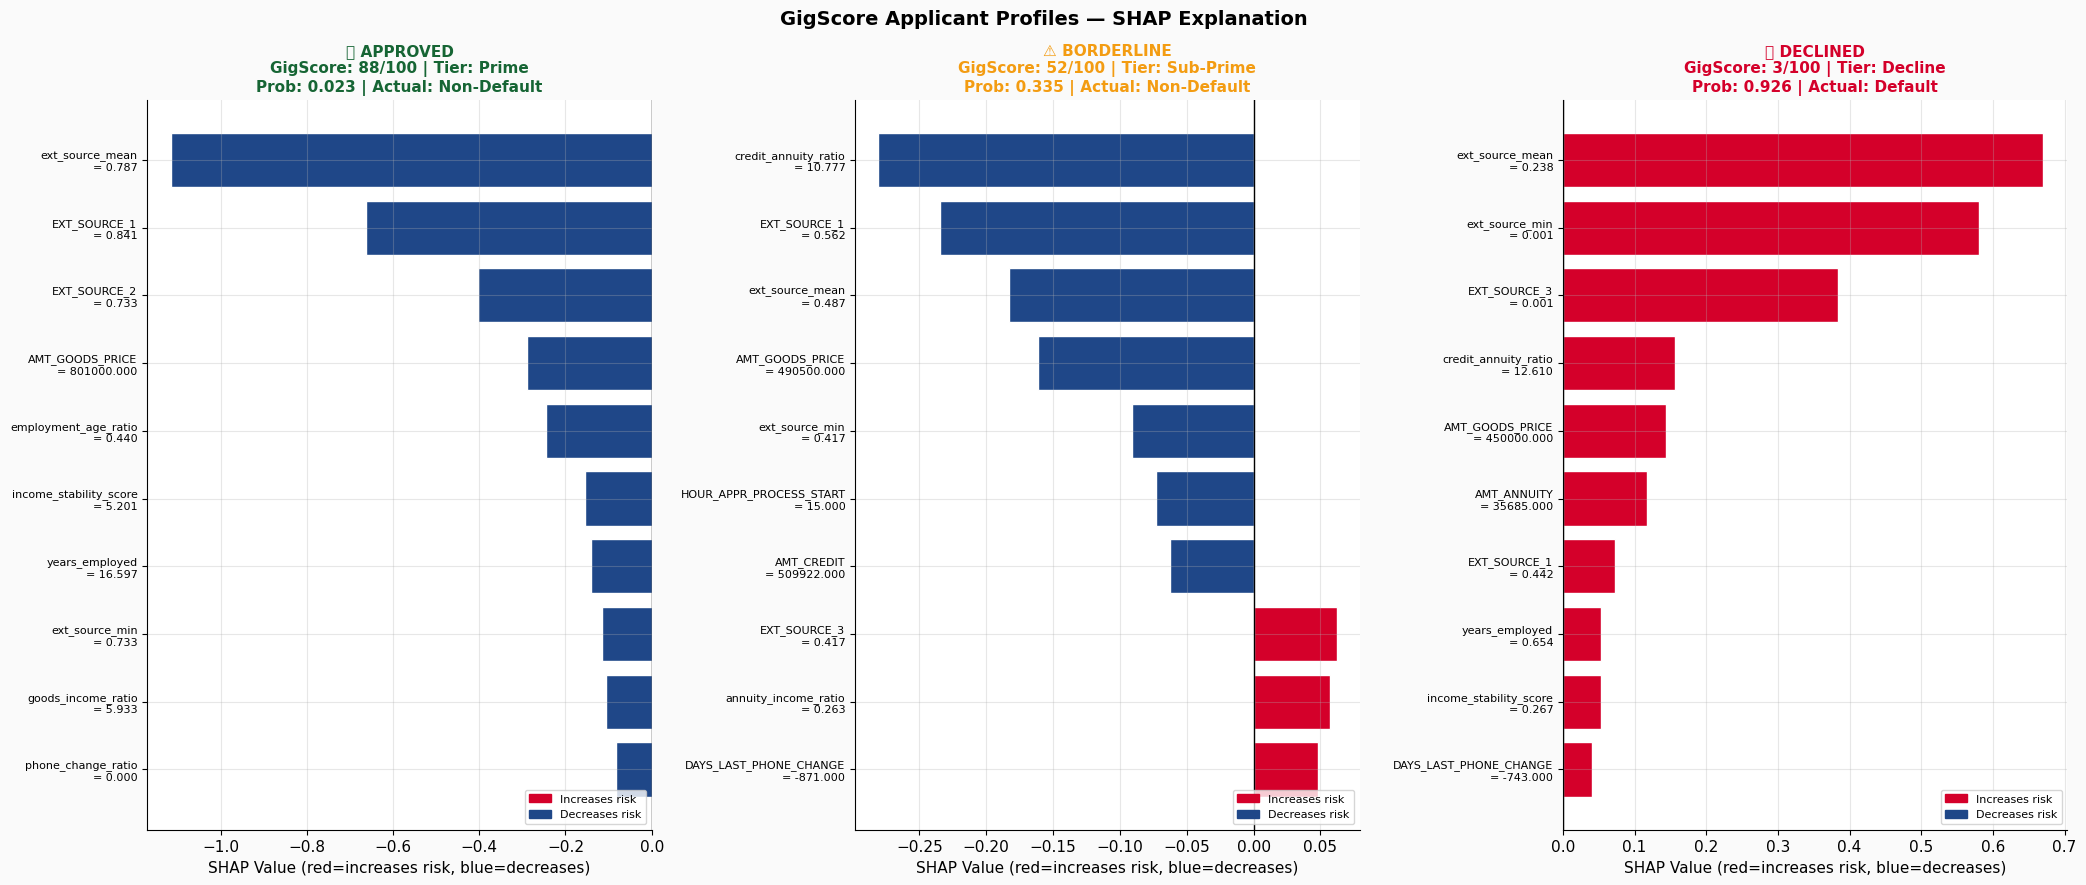

  SHAP profiles saved.


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(21, 9))
fig.suptitle("GigScore Applicant Profiles — SHAP Explanation",
             fontsize=14, fontweight='bold')

profile_colours = {'✅ APPROVED':'#166534','⚠️ BORDERLINE':ORANGE,'❌ DECLINED':BARCLAYS_EAGLE}

for ax, (label, idx) in zip(axes, profiles.items()):
    test_pos = X_test.index.get_loc(idx)
    sv       = shap_values[test_pos]
    gs       = gigscore_series[idx]
    prob     = y_prob_test[test_pos]
    act      = y_test[idx]

    shap_df = pd.DataFrame({
        'feature': X_test.columns, 'shap': sv,
        'value': X_test.iloc[test_pos].values
    }).reindex(pd.Series(np.abs(sv)).sort_values(ascending=False).index).head(10)
    top10 = shap_df.iloc[::-1]

    colours_bar = [BARCLAYS_EAGLE if v > 0 else BARCLAYS_NAVY for v in top10['shap']]
    ax.barh(range(len(top10)), top10['shap'], color=colours_bar, edgecolor='white')
    ax.set_yticks(range(len(top10)))
    ax.set_yticklabels([f"{f}\n= {v:.3f}" for f, v in
                        zip(top10['feature'], top10['value'])], fontsize=8)
    ax.axvline(0, color='black', linewidth=1)
    colour = profile_colours[label]
    ax.set_title(f"{label}\nGigScore: {gs:.0f}/100 | Tier: {assign_tier(gs)}\n"
                 f"Prob: {prob:.3f} | Actual: {'Default' if act==1 else 'Non-Default'}",
                 fontweight='bold', color=colour, fontsize=11)
    ax.set_xlabel('SHAP Value (red=increases risk, blue=decreases)')
    ax.legend(handles=[mpatches.Patch(color=BARCLAYS_EAGLE, label='Increases risk'),
                       mpatches.Patch(color=BARCLAYS_NAVY,  label='Decreases risk')],
              fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('chart_shap_profiles.png', dpi=150, bbox_inches='tight')
plt.show()
print("  SHAP profiles saved.")


## Step 8 — Save Model & Outputs for Agent 3

In [14]:
with open('gigscore_model.pkl', 'wb') as f:
    pickle.dump(gigscore_model, f)
gigscore_model.save_model('gigscore_model.json')

scores_df = pd.DataFrame({
    'applicant_id':      X_test.index,
    'gigscore':          gigscore_test,
    'default_prob':      y_prob_test,
    'tier':              tiers_test.values,
    'actual_default':    y_test.values,
    'predicted_default': y_pred_opt,
})
scores_df.to_csv('GigScore_Predictions.csv', index=False)
shap_importance.to_csv('GigScore_SHAP_Importance.csv', index=False)

top3 = []
for i in range(len(X_test)):
    sv      = shap_values[i]
    top_idx = np.abs(sv).argsort()[::-1][:3]
    top3.append({
        'applicant_id': X_test.index[i],
        'gigscore':     gigscore_test[i],
        'tier':         tiers_test.iloc[i],
        'feature_1': X_test.columns[top_idx[0]], 'shap_1': sv[top_idx[0]],
        'feature_2': X_test.columns[top_idx[1]], 'shap_2': sv[top_idx[1]],
        'feature_3': X_test.columns[top_idx[2]], 'shap_3': sv[top_idx[2]],
    })
pd.DataFrame(top3).to_csv('GigScore_SHAP_Top3.csv', index=False)

print("╔══════════════════════════════════════════════════════════════════╗")
print("║              AGENT 2 COMPLETE                                    ║")
print("╠══════════════════════════════════════════════════════════════════╣")
print(f"║  AUC        : {auc_test:.4f}                                     ║")
print(f"║  Gini       : {gini:.4f}                                     ║")
print(f"║  KS         : {ks_stat:.4f}  {'✅' if ks_stat > 0.30 else '⚠'}                                ║")
print(f"║  Accuracy   : {acc_opt:.4f}  {'✅' if acc_opt  > 0.80 else '⚠'}                                ║")
print(f"║  Precision  : {prec_opt:.4f}  {'✅' if prec_opt > 0.40 else '⚠'}                                ║")
print(f"║  Recall     : {rec_opt:.4f}  {'✅' if rec_opt  > 0.40 else '⚠'}                                ║")
print(f"║  F1         : {f1_opt:.4f}  {'✅' if f1_opt   > 0.40 else '⚠'}                                ║")
print(f"║  Overfit gap: {gap:.4f}  {'✅' if gap < 0.05 else '⚠'}                                ║")
print("╠══════════════════════════════════════════════════════════════════╣")
for t in tier_order:
    if t in tier_counts.index:
        n_t = int(tier_counts[t])
        dr  = tier_default.get(t, 0)
        print(f"║  {t:<12}: {n_t:>5,} ({n_t/len(tiers_test):.0%}) | default rate: {dr:.2%}         ║")
print("╠══════════════════════════════════════════════════════════════════╣")
print("║  📦 gigscore_model.pkl / .json                                  ║")
print("║  📄 GigScore_Predictions.csv                                    ║")
print("║  📄 GigScore_SHAP_Importance.csv / Top3.csv                     ║")
print("║  📊 7 charts + learning curve                                   ║")
print("╠══════════════════════════════════════════════════════════════════╣")
print("║  NEXT: Agent 3 — GigScore Card UI + Lender Dashboard            ║")
print("╚══════════════════════════════════════════════════════════════════╝")


╔══════════════════════════════════════════════════════════════════╗
║              AGENT 2 COMPLETE                                    ║
╠══════════════════════════════════════════════════════════════════╣
║  AUC        : 0.7289                                     ║
║  Gini       : 0.4578                                     ║
║  KS         : 0.3536  ✅                                ║
║  Accuracy   : 0.7083  ⚠                                ║
║  Precision  : 0.2071  ⚠                                ║
║  Recall     : 0.5969  ✅                                ║
║  F1         : 0.3075  ⚠                                ║
║  Overfit gap: 0.0653  ⚠                                ║
╠══════════════════════════════════════════════════════════════════╣
║  Prime       :   298 (6%) | default rate: 1.68%         ║
║  Near-Prime  :   922 (17%) | default rate: 3.47%         ║
║  Sub-Prime   :   923 (17%) | default rate: 4.55%         ║
║  Decline     : 3,184 (60%) | default rate: 15.67%         ║
╠═══